In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SOURCE_DATA_DIR = Path(os.environ["SOURCE_DATA_DIR"])
OUTPUT_DATA_DIR = Path(os.environ["OUTPUT_DATA_DIR"])


In [2]:
import sys
sys.path.insert(0, str(Path("__file__").resolve().parent.parent))
from analysis.clustering import load_scene_patterns
from analysis.trace_plots import (
    plot_scene_clusters,
    plot_scene_cluster_panels,
    CLUSTER_COLORS,
    default_background_dir,
)

In [3]:
# Plot config — edit to taste.
# Palette/marker constants and the plotting function now live in
# analysis/trace_plots.py so the rendering logic is in one importable place.

# Color each trace by its cluster ("cluster") or by clip outcome
# ("outcome": green = completed, red = death).
COLOR_BY = "cluster"

# Scene background PNGs are drawn under the traces when a matching
# <scene_id>.png exists in this dir; otherwise plots fall back to a plain
# y-flipped axis. These images don't ship with the dataset and must be
# generated separately (see mario.scenes/code/deprecated/make_images/).
# Set BACKGROUND_DIR = None to disable the overlay entirely.
BACKGROUND_DIR = default_background_dir(SOURCE_DATA_DIR)

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_summary.png


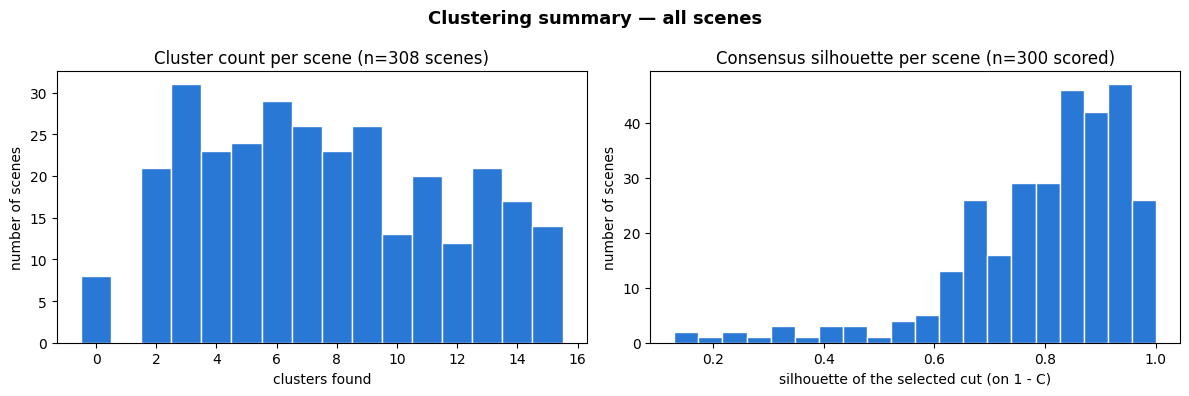

In [4]:
# --- Summary across all clustered scenes: cluster count & consensus silhouette ---
# The second panel used to be the HDBSCAN noise fraction. The consensus step is Ward
# now, which assigns every trace, so that quantity is identically zero and says nothing.
# The silhouette the cut was selected on is the informative per-scene number in its place.
cluster_files = sorted((OUTPUT_DATA_DIR / "clusters").glob("*_clusters.json"))

scene_ids, n_clusters_list, silhouette_list = [], [], []
for f in cluster_files:
    result = json.loads(f.read_text())
    labels = result["labels"]
    n_found = len(set(l for l in labels if l != -1))
    consensus = (result.get("stability") or {}).get("consensus") or {}
    scene_ids.append(result["scene"])
    n_clusters_list.append(n_found)
    silhouette_list.append(consensus.get("silhouette"))

# None where a scene was too small for any cut to be selected (see the fallback in
# analysis.stability.ward_consensus_labels).
scored = [s for s in silhouette_list if s is not None]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(n_clusters_list, bins=range(0, max(n_clusters_list) + 2),
             color=CLUSTER_COLORS[0], edgecolor="#fcfcfb", align="left")
axes[0].set_xlabel("clusters found")
axes[0].set_ylabel("number of scenes")
axes[0].set_title(f"Cluster count per scene (n={len(scene_ids)} scenes)")

axes[1].hist(scored, bins=20, color=CLUSTER_COLORS[0], edgecolor="#fcfcfb")
axes[1].set_xlabel("silhouette of the selected cut (on 1 - C)")
axes[1].set_ylabel("number of scenes")
axes[1].set_title(f"Consensus silhouette per scene (n={len(scored)} scored)")

fig.suptitle("Clustering summary — all scenes", fontsize=13, fontweight="bold")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_summary.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_silhouette.png


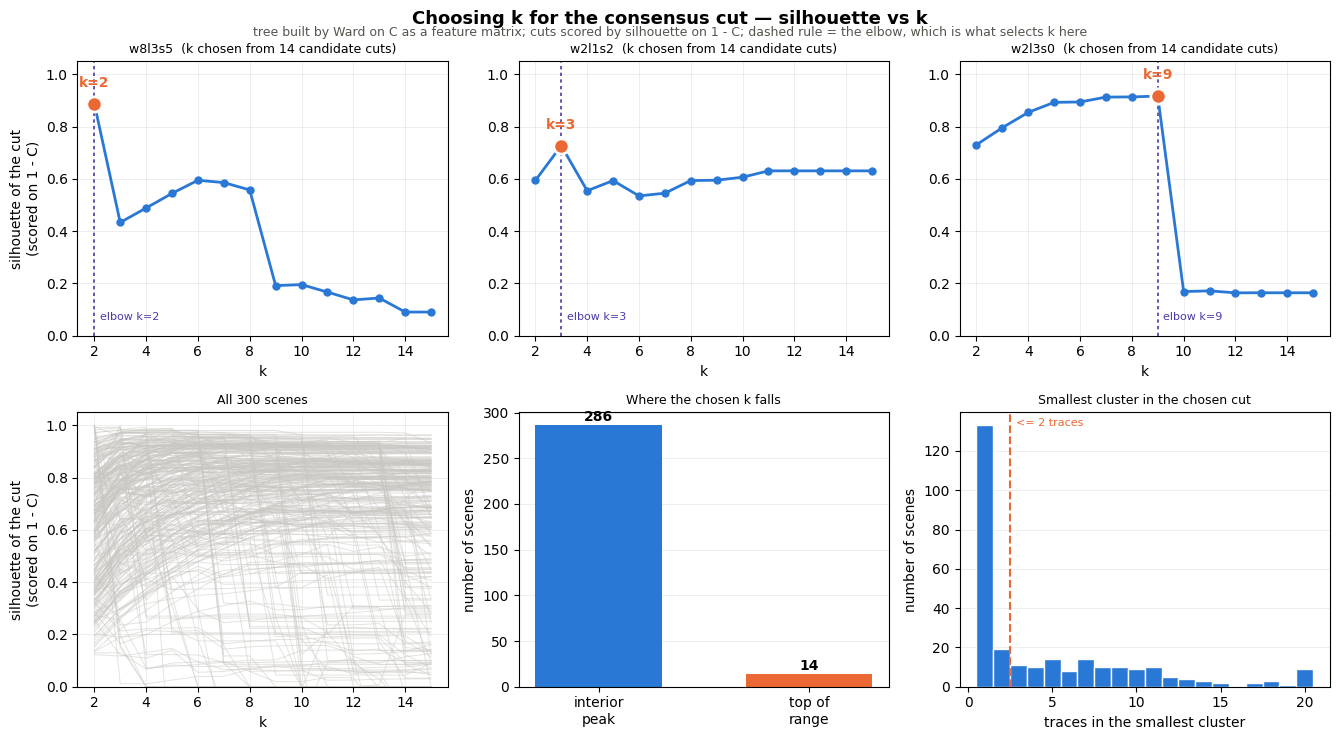

In [5]:
# --- How the consensus cut is chosen: silhouette vs k ---
# Ward gives a tree, not a partition; k comes from the silhouette scored on 1 - C.
# The dashed vertical rule marks the *elbow* — the last k before the curve drops off a cliff
# (analysis.stability.elbow_k). It is a reading of the curve's shape rather than its
# maximum, it is recorded on every run, and --consensus-k-rule decides whether it also
# selects. The caption below reads that setting off the files rather than asserting it,
# so this figure stays honest if the corpus is re-cut under a different rule.
# Where the elbow and the peak disagree by a lot, the argmax has climbed past a cliff
# into the flat tail, which is the same failure the bottom-right panel counts.
# The whole curve is stored per scene in stability.consensus.k_candidates, so this
# plots what the selection actually saw, and the rule is the plain one: highest
# silhouette wins. Both guards on that rule ship off (consensus_tol = 0,
# consensus_min_cluster_size = 1), so every cut from k=2 up is a candidate and the
# curves run the full range unless the scene has too few traces for k_max cuts.
#
# The bottom-right panel is the one to read sceptically: it counts how many traces
# are in the *smallest* cluster of each chosen cut. The silhouette cannot penalise a
# singleton — sklearn scores one at 0, and a trace that never co-clustered already
# scored ~0 inside its parent — so a cut that peels off dust costs nothing and the
# argmax will take it.
from collections import Counter
from matplotlib.ticker import MaxNLocator

from analysis.stability import elbow_k

curves = {}
for f in sorted((OUTPUT_DATA_DIR / "clusters").glob("*_clusters.json")):
    r = json.loads(f.read_text())
    c = (r.get("stability") or {}).get("consensus") or {}
    if c.get("k_candidates"):
        curves[r["scene"]] = c

EXAMPLES = ["w8l3s5", "w2l1s2", "w2l3s0"]
LINE, PICK, FAINT = CLUSTER_COLORS[0], CLUSTER_COLORS[1], "#c9c7c2"
# A third hue: this figure already spends orange (PICK) on the chosen cut, so the
# elbow cannot reuse the dashboard's warm marker without the two reading as one
# thing. Dashed and vertical either way — it marks one k, not a series.
ELBOW = CLUSTER_COLORS[6]

fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))

for ax, scene in zip(axes[0], EXAMPLES):
    c = curves[scene]
    ks = [r["k"] for r in c["k_candidates"]]
    sil = [r["silhouette"] for r in c["k_candidates"]]
    ax.plot(ks, sil, "-o", color=LINE, lw=2, ms=5, zorder=2)
    ax.plot([c["k"]], [c["silhouette"]], "o", color=PICK, ms=11,
            mec="#fcfcfb", mew=2, zorder=3)
    ax.annotate(f"k={c['k']}", (c["k"], c["silhouette"]), textcoords="offset points",
                xytext=(0, 12), ha="center", color=PICK, fontweight="bold")
    # Recorded in the file on newer runs; derived from the stored curve otherwise —
    # it is a pure function of that curve either way.
    e = c.get("elbow") or elbow_k(c["k_candidates"])
    if e["k"] is not None:
        ax.axvline(e["k"], color=ELBOW, lw=1.2, ls=(0, (2, 2)), zorder=1)
        ax.annotate(f"elbow k={e['k']}", (e["k"], 0.06), color=ELBOW, fontsize=8,
                    ha="right" if e["k"] > ks[len(ks) // 2] else "left",
                    textcoords="offset points",
                    xytext=(-4 if e["k"] > ks[len(ks) // 2] else 4, 0))
    ax.set_title(f"{scene}  (k chosen from {len(ks)} candidate cuts)", fontsize=9)
    ax.set_xlabel("k"); ax.set_ylim(0, 1.05)
    # k is discrete — never let matplotlib offer half a cluster.
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.25, lw=0.6); ax.set_axisbelow(True)
axes[0][0].set_ylabel("silhouette of the cut\n(scored on 1 - C)")

# Every curve at once — the shape of the selection problem across the corpus.
ax = axes[1][0]
for c in curves.values():
    ax.plot([r["k"] for r in c["k_candidates"]],
            [r["silhouette"] for r in c["k_candidates"]],
            "-", color=FAINT, lw=0.7, alpha=0.5, zorder=1)
ax.set_title(f"All {len(curves)} scenes", fontsize=9)
ax.set_xlabel("k"); ax.set_ylabel("silhouette of the cut\n(scored on 1 - C)")
ax.set_ylim(0, 1.05); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(alpha=0.25, lw=0.6); ax.set_axisbelow(True)

# Does the maximum sit inside the candidate range, or at its top edge?
ax = axes[1][1]
interior = sum(1 for c in curves.values()
               if c["k"] != max(r["k"] for r in c["k_candidates"]))
at_top = len(curves) - interior
bars = ax.bar(["interior\npeak", "top of\nrange"], [interior, at_top],
              color=[LINE, PICK], width=0.6)
for b, v in zip(bars, [interior, at_top]):
    ax.annotate(str(v), (b.get_x() + b.get_width() / 2, v), ha="center",
                textcoords="offset points", xytext=(0, 3), fontweight="bold")
ax.set_title("Where the chosen k falls", fontsize=9)
ax.set_ylabel("number of scenes")
ax.grid(alpha=0.25, lw=0.6, axis="y"); ax.set_axisbelow(True)

# What the chosen cut actually costs: the size of its smallest cluster. With no floor
# on the Ward cut this is the honest check on whether the argmax bought resolution or
# dust — a bar at 1 is a singleton the silhouette was structurally unable to object to.
ax = axes[1][2]
smallest = [min(r["min_size"] for r in c["k_candidates"] if r["k"] == c["k"])
            for c in curves.values()
            if any(r["k"] == c["k"] for r in c["k_candidates"])]
ax.hist(smallest, bins=range(1, 22), color=LINE, edgecolor="#fcfcfb", align="left")
ax.axvline(2.5, color=PICK, lw=1.5, ls="--")
ax.annotate("<= 2 traces", (2.5, ax.get_ylim()[1]), color=PICK, fontsize=8,
            textcoords="offset points", xytext=(4, -10))
ax.set_title("Smallest cluster in the chosen cut", fontsize=9)
ax.set_xlabel("traces in the smallest cluster"); ax.set_ylabel("number of scenes")
ax.grid(alpha=0.25, lw=0.6, axis="y"); ax.set_axisbelow(True)

fig.suptitle("Choosing k for the consensus cut — silhouette vs k",
             fontsize=13, fontweight="bold")
# Two matrices, two jobs: Ward builds the tree from C as a feature matrix (Euclidean
# between co-occurrence profiles); the silhouette scores the resulting cuts on 1 - C
# as a precomputed distance. Spelling both out because the figure otherwise reads as
# though 1 - C were Ward's input, which it is not.
# Which rule actually made this corpus, taken from the files themselves.
rules = Counter(c.get("rule", "silhouette") for c in curves.values())
elbow_selects = rules.most_common(1)[0][0].startswith("elbow")
fig.text(0.5, 0.945, "tree built by Ward on C as a feature matrix; cuts scored by "
         "silhouette on 1 - C; dashed rule = the elbow, "
         + ("which is what selects k here" if elbow_selects
            else "recorded but not selecting"),
         ha="center", fontsize=9, color="#57544e")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_silhouette.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


In [6]:
# --- Detail plots: trajectories colored by cluster, for a handful of example scenes ---
# Edit this list to inspect other scenes (must have a matching <scene_id>_clusters.json).
SCENES_TO_PLOT = [scene_ids[i] for i in np.linspace(0, len(scene_ids) - 1, 4).astype(int)]
print("Plotting detail for:", SCENES_TO_PLOT)


Plotting detail for: ['w1l1s0', 'w3l3s5', 'w6l2s16', 'w8l3s9']


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w1l1s0.png


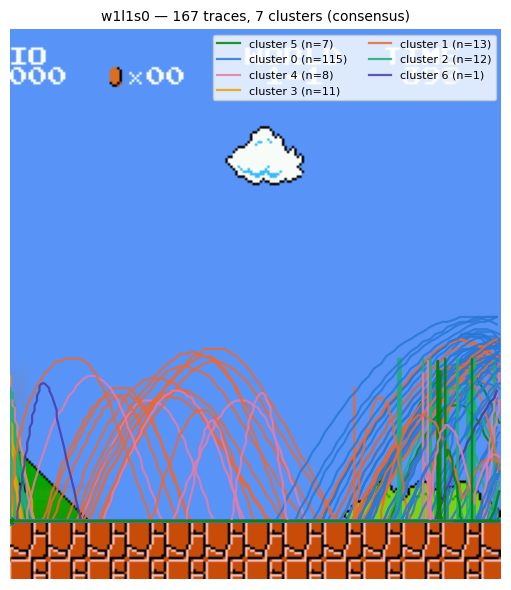

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w3l3s5.png


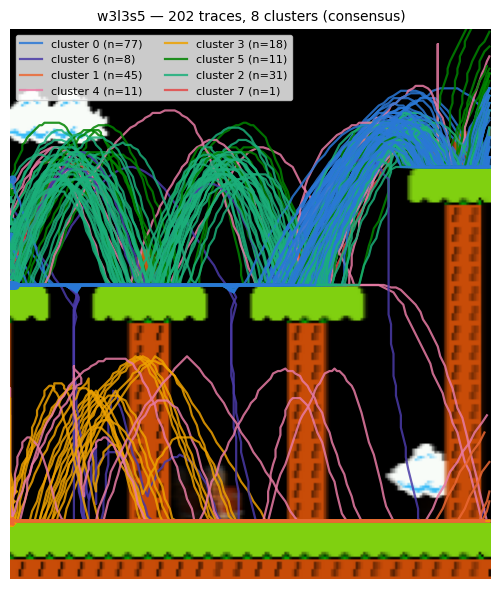

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w6l2s16.png


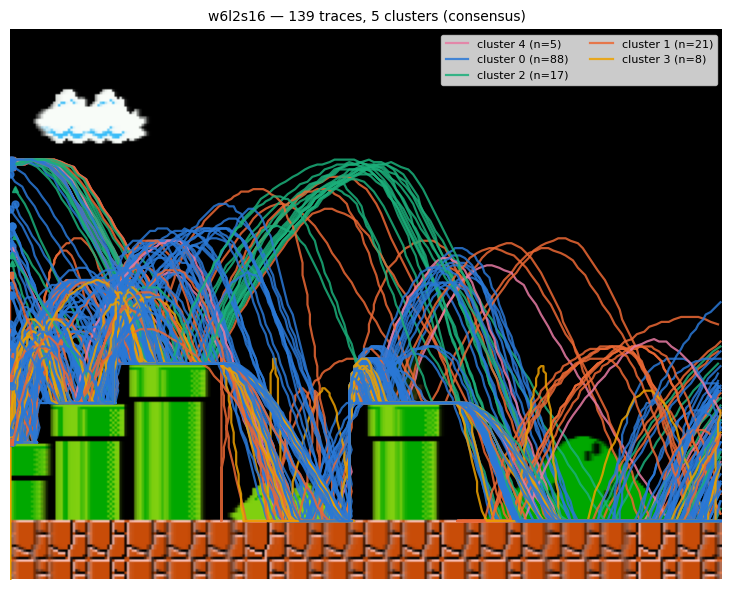

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w8l3s9.png


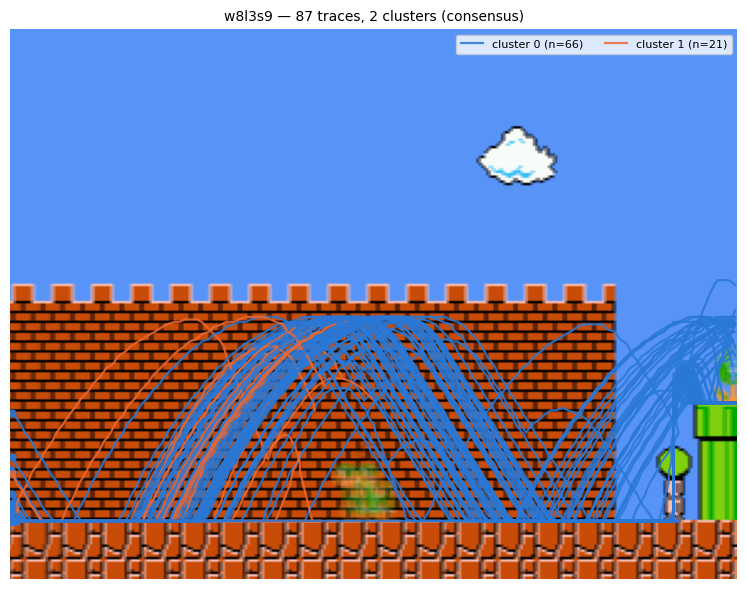

In [7]:
# plot_scene_clusters now lives in analysis/trace_plots.py (imported above).
for scene_id in SCENES_TO_PLOT:
    plot_scene_clusters(
        scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR,
        color_by=COLOR_BY, background_dir=BACKGROUND_DIR,
    )

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w1l1s0_panels.png


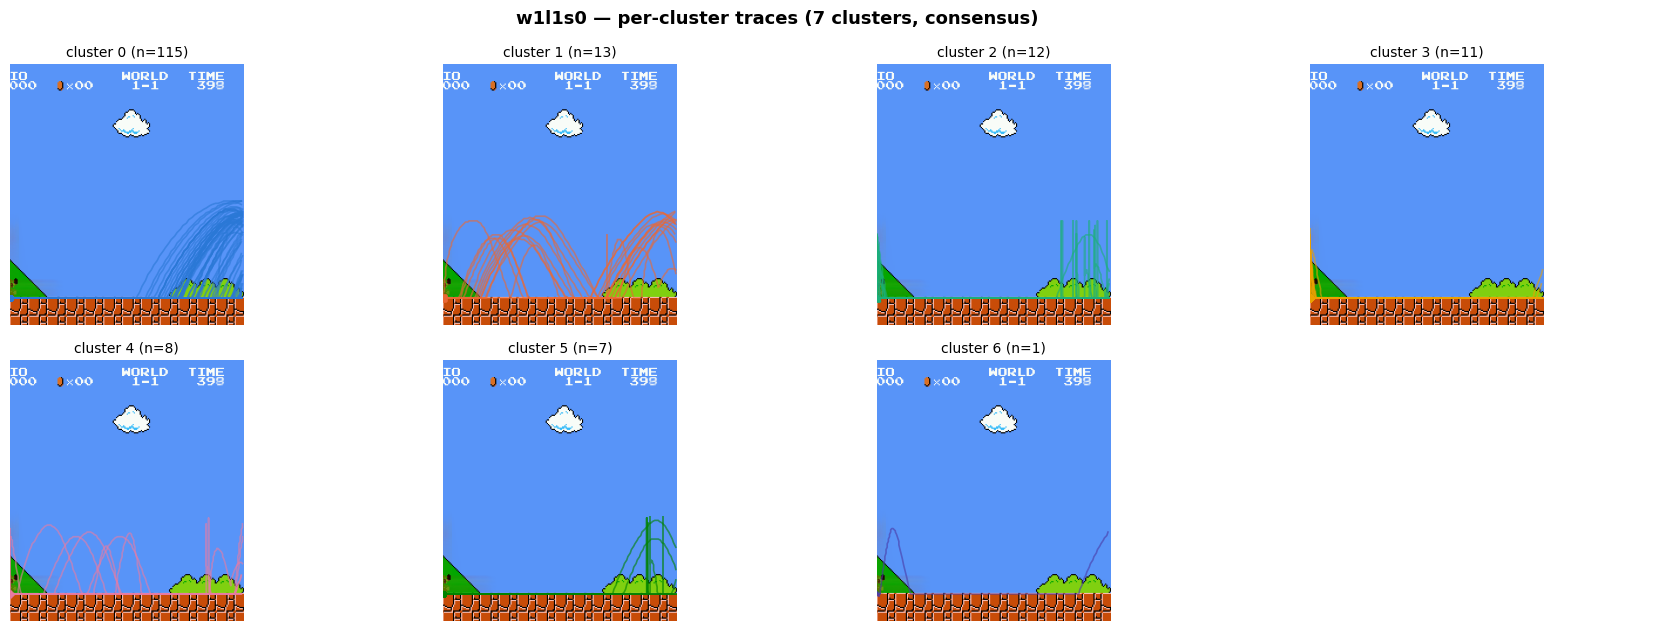

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w3l3s5_panels.png


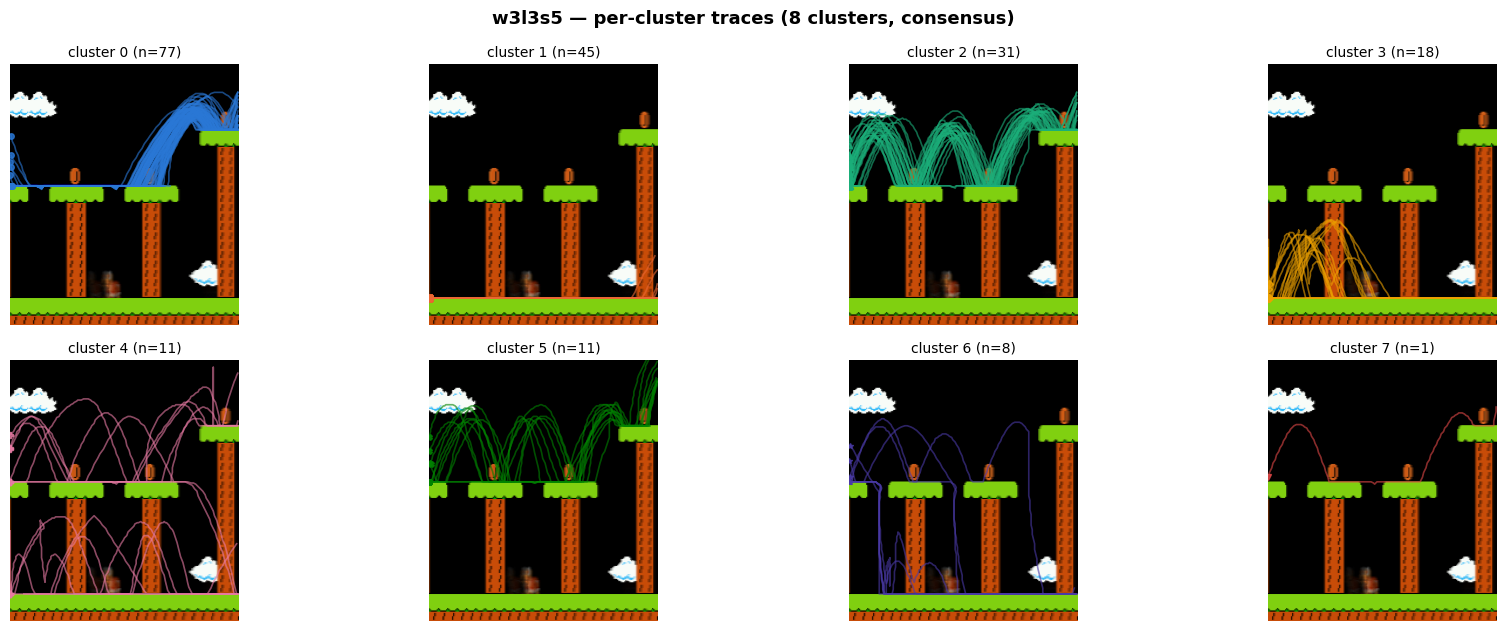

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w6l2s16_panels.png


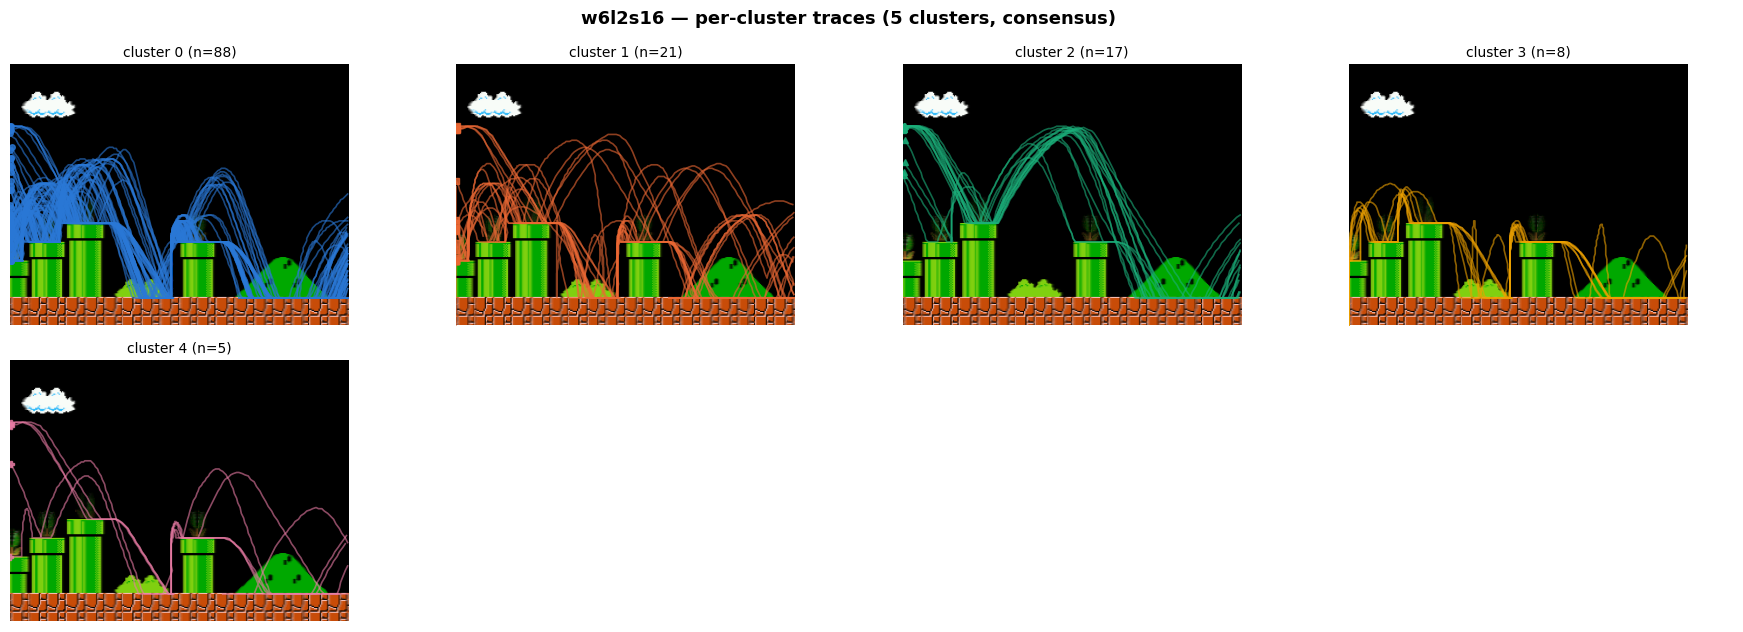

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w8l3s9_panels.png


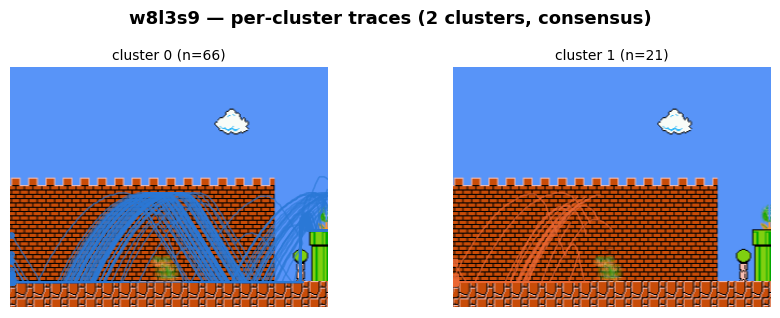

In [8]:
# --- Per-cluster panels: one subplot per cluster for a scene, all in one image ---
# Splits a scene's traces so each cluster gets its own panel (shared axes),
# making individual cluster shapes easy to read. Saves
# figure_clustering_<scene>_panels.png. Edit SCENES_TO_PLOT above to pick scenes.
for scene_id in SCENES_TO_PLOT:
    plot_scene_cluster_panels(
        scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR,
        background_dir=BACKGROUND_DIR,
    )

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w1l1s0_panels_by_subject.png


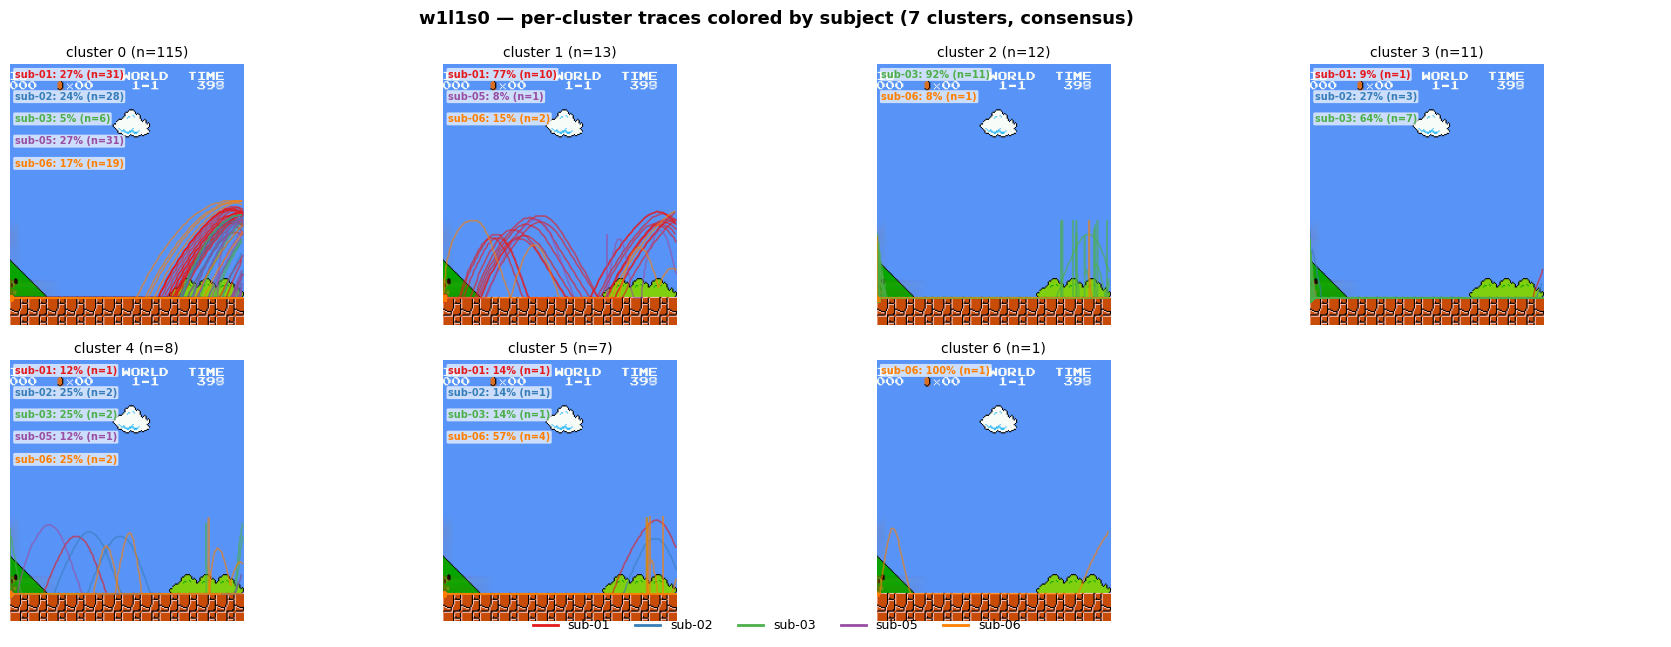

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w3l3s5_panels_by_subject.png


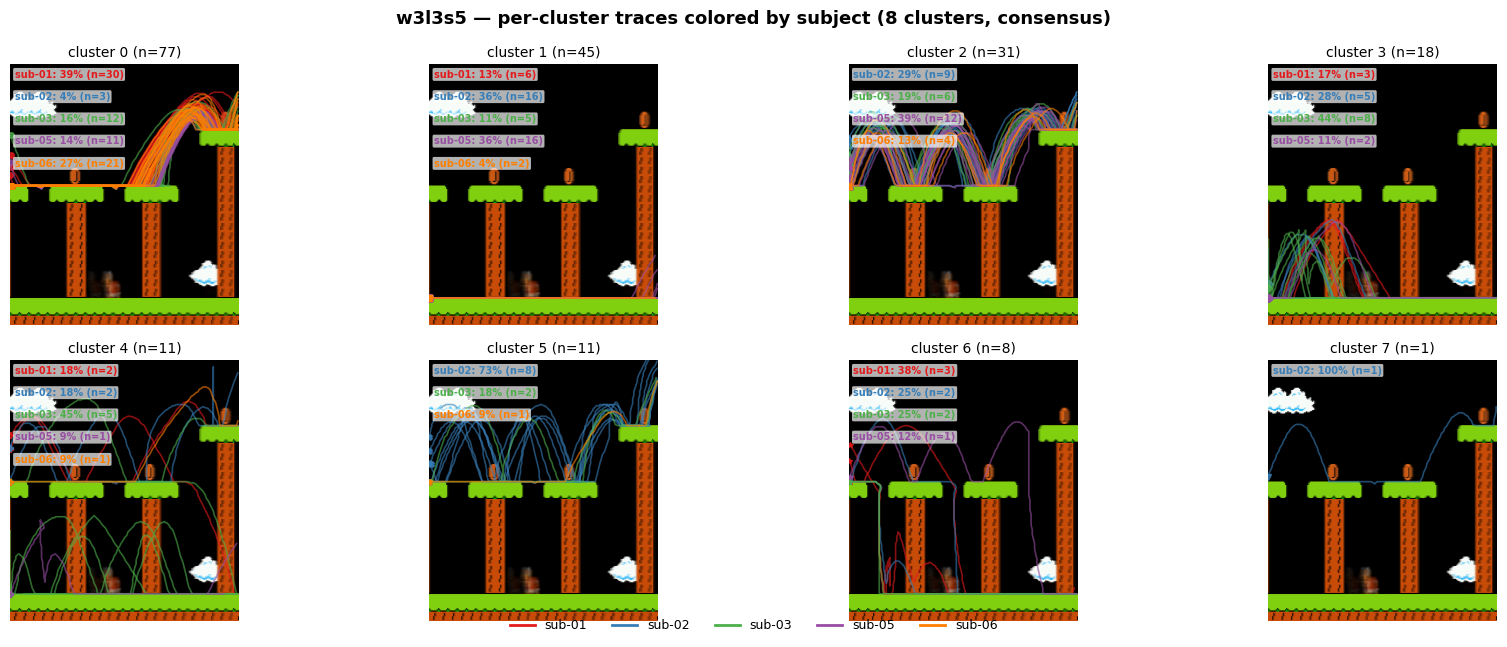

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w6l2s16_panels_by_subject.png


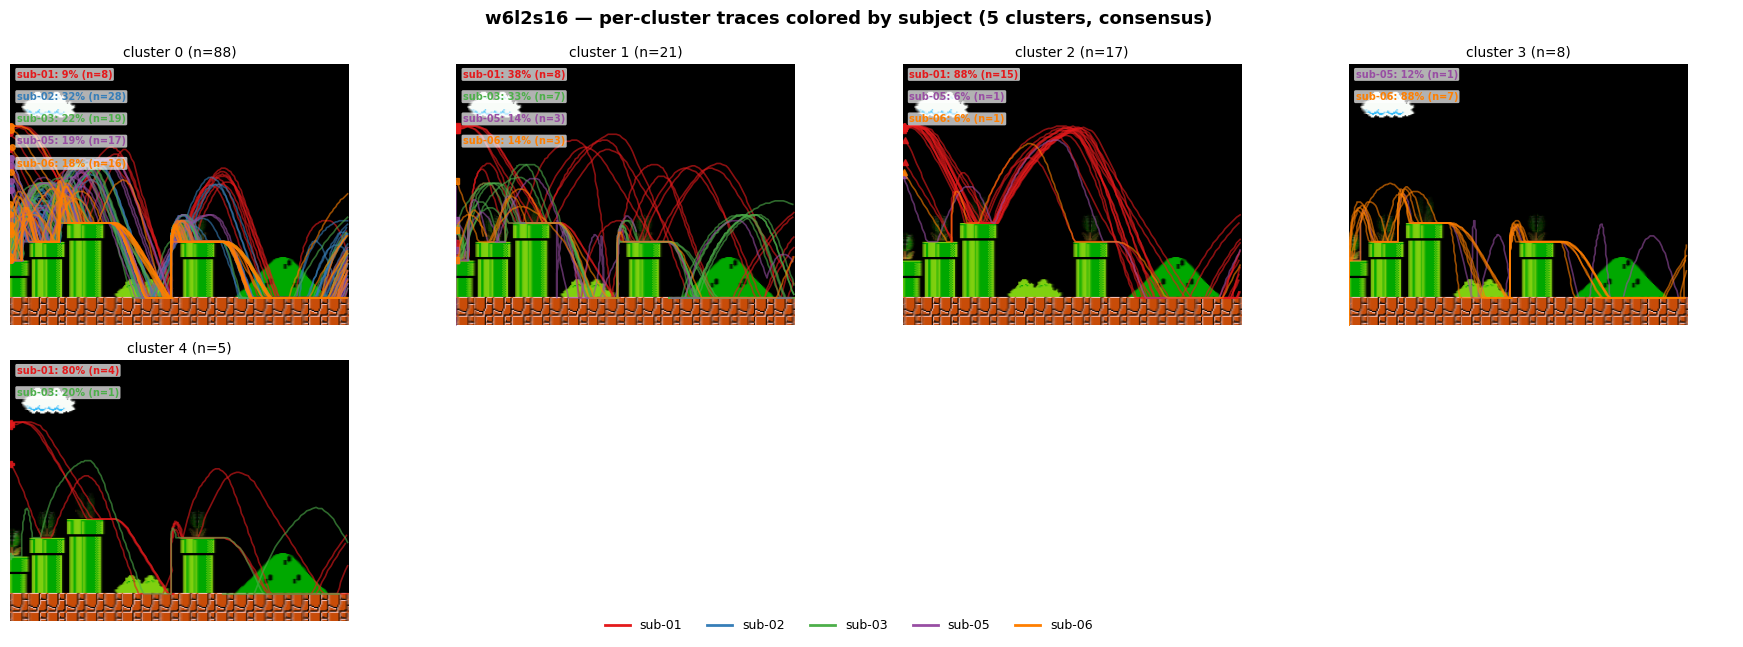

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_w8l3s9_panels_by_subject.png


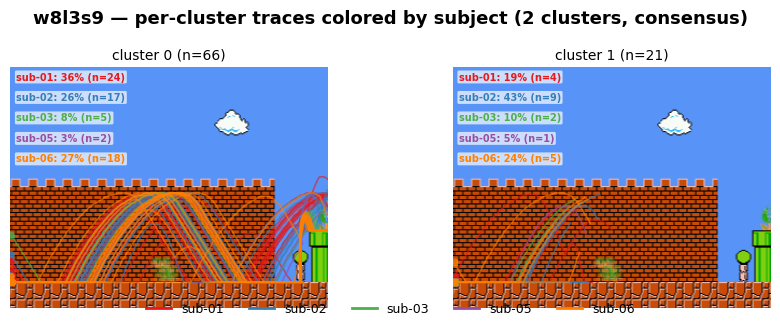

In [9]:
# --- Per-cluster panels colored by SUBJECT (which player is which) ---
# Same per-cluster small-multiples as above, but each trace is colored by its
# player (color_by="subject") instead of a single cluster color, with a subject
# legend. This reveals the per-subject composition of every cluster — e.g. whether
# a cluster is one player's signature route or a strategy shared across players.
# Saves figure_clustering_<scene>_panels_by_subject.png (distinct from the
# cluster-colored panels, so both are kept).
for scene_id in SCENES_TO_PLOT:
    plot_scene_cluster_panels(
        scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR,
        color_by="subject", background_dir=BACKGROUND_DIR,
    )


In [10]:
# --- Cluster stats by scene category (pattern tag) ---
# scenes_mastersheet.csv tags each scene with one or more design-pattern labels
# (e.g. "2-Horde", "Gap stair valley"); a scene can carry several tags at once,
# so it contributes to each of its categories below (see analysis/clustering.py
# load_scene_patterns and source_data/CONTENT.md).
patterns_long = load_scene_patterns(SOURCE_DATA_DIR)

scene_stats = pd.DataFrame({
    "scene_id": scene_ids,
    "n_clusters": n_clusters_list,
    "silhouette": silhouette_list,
})
category_stats = patterns_long.merge(scene_stats, on="scene_id", how="inner")
print(f"{category_stats['pattern'].nunique()} categories, "
      f"{category_stats['scene_id'].nunique()} scenes with a cluster result and a category tag")


27 categories, 305 scenes with a cluster result and a category tag


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_by_category.png


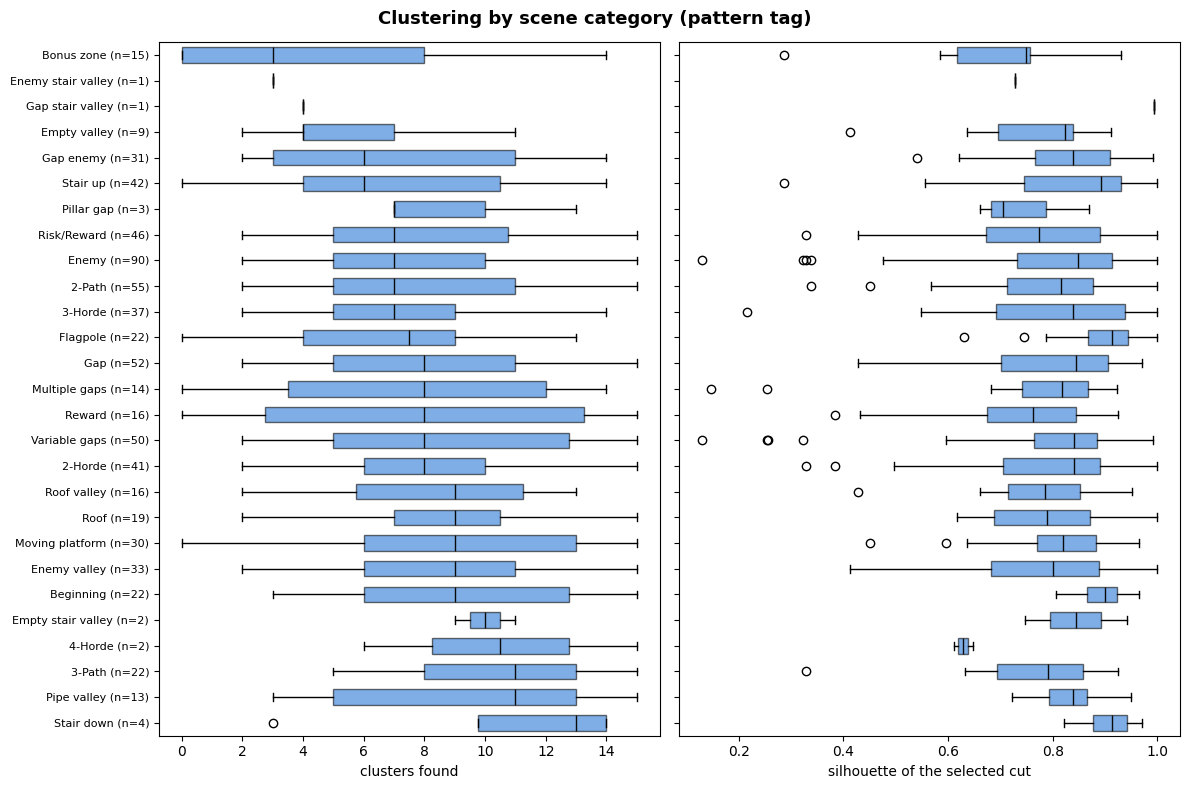

In [11]:
order = (category_stats.groupby("pattern")["n_clusters"].median()
         .sort_values(ascending=False).index)

fig, axes = plt.subplots(1, 2, figsize=(12, 8), sharey=True)

for ax, col, xlabel in zip(
    axes,
    ["n_clusters", "silhouette"],
    ["clusters found", "silhouette of the selected cut"],
):
    # dropna: scenes whose ensemble carried no signal have no silhouette (see
    # selection="no_ensemble_signal"), and boxplot cannot take NaN.
    data = [category_stats.loc[category_stats["pattern"] == cat, col].dropna()
            for cat in order]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6,
                     medianprops={"color": "#0b0b0b"})
    for box in bp["boxes"]:
        box.set(facecolor=CLUSTER_COLORS[0], alpha=0.6, edgecolor="#0b0b0b")
    ax.set_xlabel(xlabel)

axes[0].set_yticks(range(1, len(order) + 1))
n_scenes_per_cat = category_stats.groupby("pattern")["scene_id"].nunique()
axes[0].set_yticklabels([f"{cat} (n={n_scenes_per_cat[cat]})" for cat in order], fontsize=8)

fig.suptitle("Clustering by scene category (pattern tag)", fontsize=13, fontweight="bold")
fig.tight_layout()

out_path = OUTPUT_DATA_DIR / "clusters" / "figure_clustering_by_category.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
print(f"Saved -> {out_path}")
plt.show()


Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_category_gap_stair_valley.png


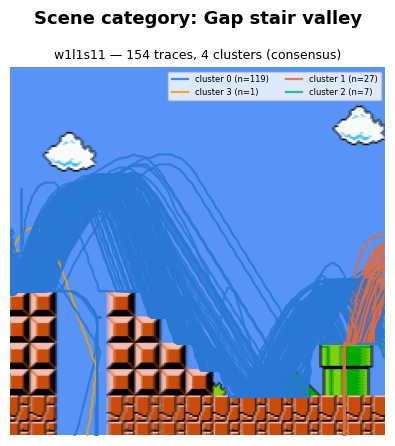

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_category_2-horde.png


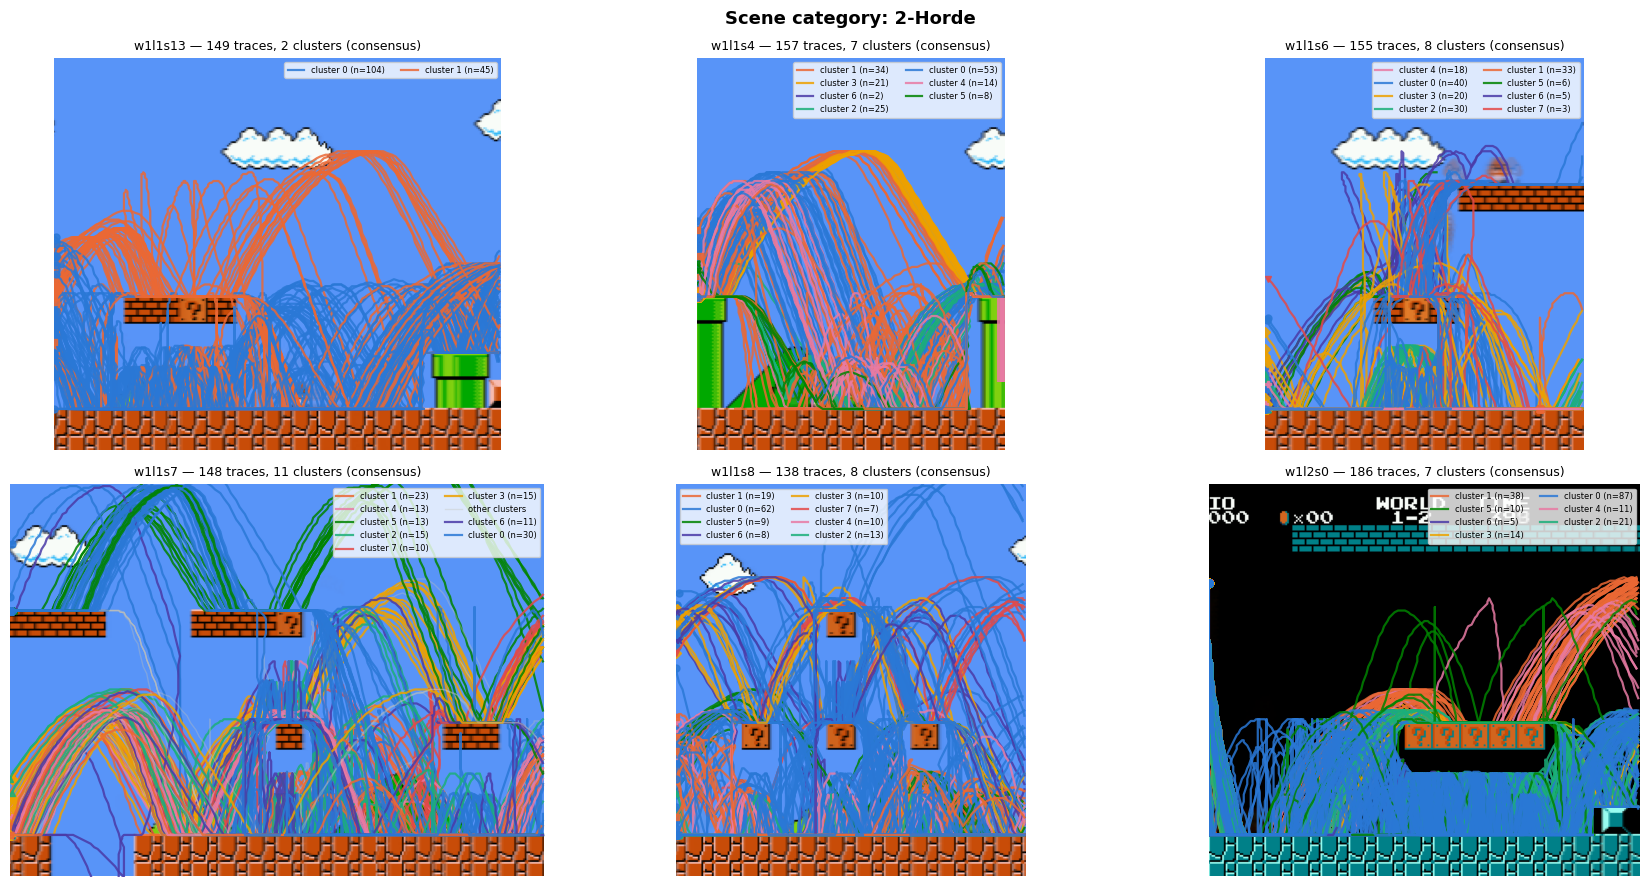

Saved -> /home/cleode5a7/Desktop/werk/neuromod/Mario_behaviour/output_data/clusters/figure_clustering_category_flagpole.png


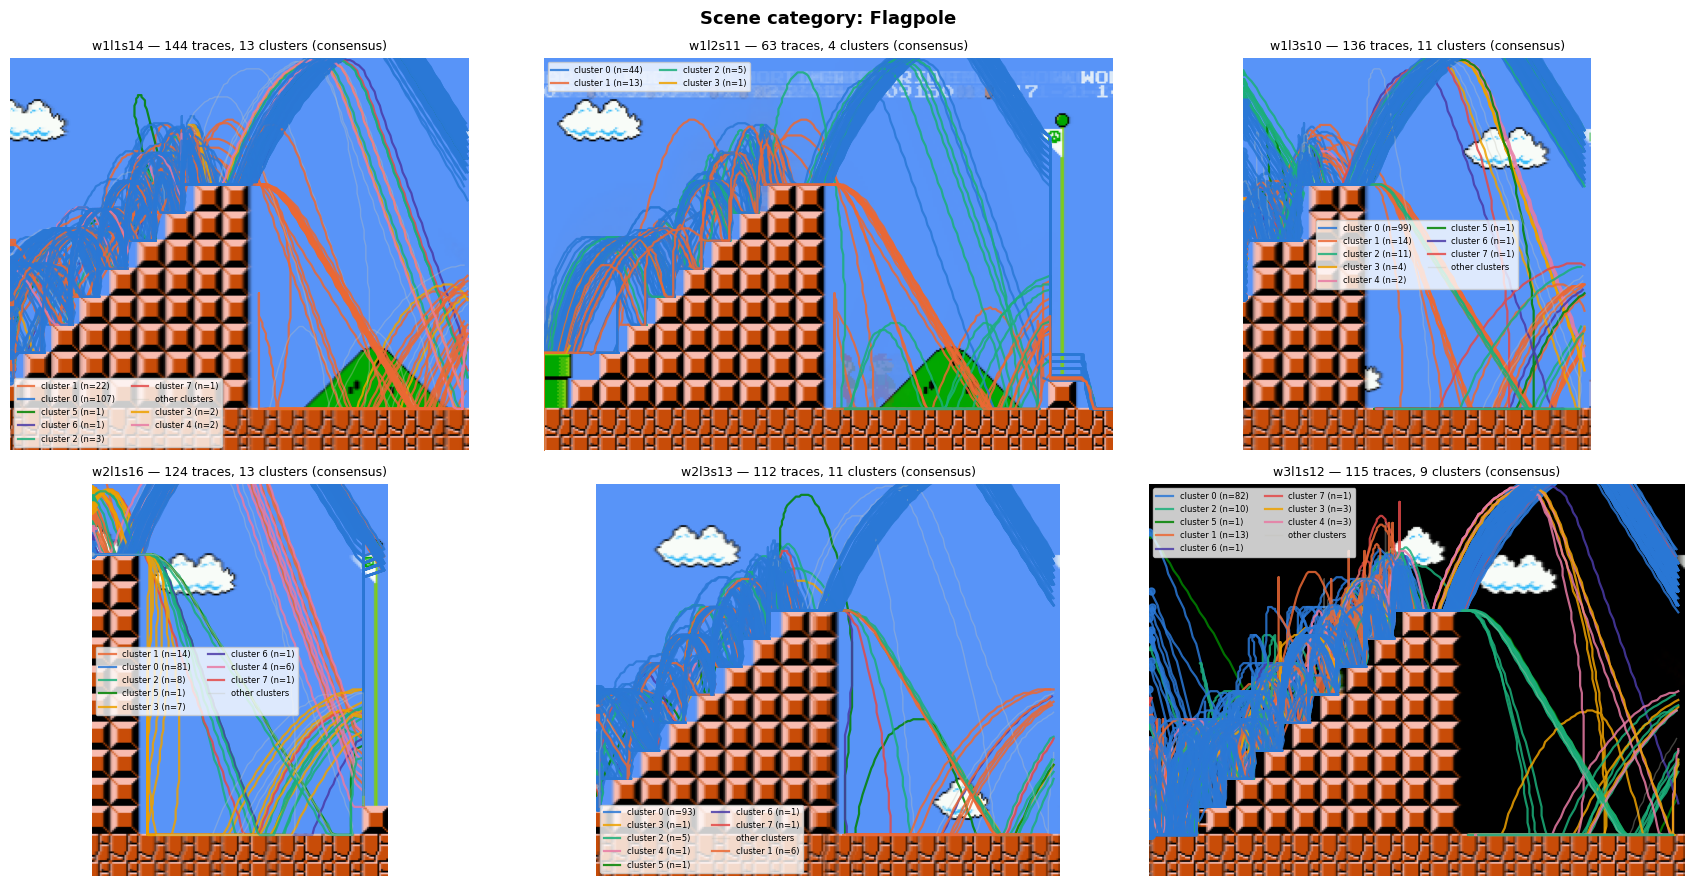

In [12]:
# --- Detail plots: one small-multiples figure per category, one subplot per scene ---
# Edit this list to inspect other categories (must be a column in scenes_mastersheet.csv).
CATEGORIES_TO_PLOT = ["Gap stair valley", "2-Horde", "Flagpole"]
MAX_SCENES_PER_CATEGORY = 6  # cap so the grid stays legible; edit freely


def plot_category_grid(category):
    scenes_in_cat = sorted(patterns_long.loc[patterns_long["pattern"] == category, "scene_id"].unique())
    if not scenes_in_cat:
        print(f"No scenes tagged '{category}', skipping.")
        return
    scenes_in_cat = scenes_in_cat[:MAX_SCENES_PER_CATEGORY]

    cols = min(3, len(scenes_in_cat))
    rows = (len(scenes_in_cat) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4.5 * rows), squeeze=False)

    for i, scene_id in enumerate(scenes_in_cat):
        ax = axes[i // cols][i % cols]
        plot_scene_clusters(
            scene_id, SOURCE_DATA_DIR, OUTPUT_DATA_DIR, ax=ax,
            color_by=COLOR_BY, background_dir=BACKGROUND_DIR,
            title_fontsize=9, legend_fontsize=6,
        )
    for i in range(len(scenes_in_cat), rows * cols):
        axes[i // cols][i % cols].axis("off")

    fig.suptitle(f"Scene category: {category}", fontsize=13, fontweight="bold")
    fig.tight_layout()

    slug = category.lower().replace(" ", "_").replace("/", "-")
    out_path = OUTPUT_DATA_DIR / "clusters" / f"figure_clustering_category_{slug}.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    print(f"Saved -> {out_path}")
    plt.show()


for category in CATEGORIES_TO_PLOT:
    plot_category_grid(category)